In [1]:
import pandas as pd                          
import numpy as np

df=pd.read_csv("customer_churn_data-raw.csv")      # Loading the dataset into a pandas dataframe
df.head(10)

,Customer_ID,Gender,Age,Tenure_Months,Contract_Type,Payment_Method,Monthly_Charges,Total_Charges,Internet_Service,Tech_Support,Streaming_Service,Number_of_Complaints,Support_Calls,Last_Login_Days,Satisfaction_Score,Churn
0,C100000,Male,20,62,One Year,Bank Transfer,98.56,6066.68,No Internet,Yes,No,2,0,13,6.4,0
1,C100001,Female,24,4,Month-to-Month,Electronic Check,60.78,232.84,DSL,Yes,No,0,2,25,7.9,1
2,C100002,Female,43,6,Month-to-Month,Electronic Check,103.17,571.54,No Internet,No,Yes,0,5,22,6.3,1
3,C100003,Female,24,72,Month-to-Month,Bank Transfer,68.68,5278.75,DSL,No,Yes,0,2,18,6.1,0
4,C100004,Male,51,16,Month-to-Month,Electronic Check,110.19,1637.33,DSL,No,No,1,3,10,8.2,1
5,C100005,Male,37,38,Month-to-Month,Bank Transfer,105.68,3847.91,Fiber Optic,No,No,4,2,30,4.6,1
6,C100006,Male,39,49,Two Year,UPI,62.06,3214.43,No Internet,No,Yes,3,1,6,7.5,0
7,C100007,Female,35,61,Two Year,Credit Card,82.56,5390.16,DSL,No,Yes,0,3,9,9.0,0
8,C100008,Female,47,65,Month-to-Month,Electronic Check,80.40,5364.41,Fiber Optic,Yes,Yes,4,1,1,7.4,0
9,C100009,Female,47,50,Month-to-Month,Electronic Check,87.87,4223.87,DSL,No,No,3,1,3,7.7,0


In [2]:
df.shape

(10000, 16)

In [3]:
df.columns

Index(['Customer_ID', 'Gender', 'Age', 'Tenure_Months', 'Contract_Type',
       'Payment_Method', 'Monthly_Charges', 'Total_Charges',
       'Internet_Service', 'Tech_Support', 'Streaming_Service',
       'Number_of_Complaints', 'Support_Calls', 'Last_Login_Days',
       'Satisfaction_Score', 'Churn'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           10000 non-null  object 
 1   Gender                10000 non-null  object 
 2   Age                   10000 non-null  int64  
 3   Tenure_Months         10000 non-null  int64  
 4   Contract_Type         10000 non-null  object 
 5   Payment_Method        9950 non-null   object 
 6   Monthly_Charges       10000 non-null  float64
 7   Total_Charges         9900 non-null   float64
 8   Internet_Service      10000 non-null  object 
 9   Tech_Support          10000 non-null  object 
 10  Streaming_Service     10000 non-null  object 
 11  Number_of_Complaints  10000 non-null  int64  
 12  Support_Calls         10000 non-null  int64  
 13  Last_Login_Days       10000 non-null  int64  
 14  Satisfaction_Score    9900 non-null   float64
 15  Churn               

Data Cleaning

In [5]:
df.isna().sum()

Customer_ID               0
Gender                    0
Age                       0
Tenure_Months             0
Contract_Type             0
Payment_Method           50
Monthly_Charges           0
Total_Charges           100
Internet_Service          0
Tech_Support              0
Streaming_Service         0
Number_of_Complaints      0
Support_Calls             0
Last_Login_Days           0
Satisfaction_Score      100
Churn                     0
dtype: int64

In [6]:
(df.isnull().sum()/len(df))*100

Customer_ID             0.0
Gender                  0.0
Age                     0.0
Tenure_Months           0.0
Contract_Type           0.0
Payment_Method          0.5
Monthly_Charges         0.0
Total_Charges           1.0
Internet_Service        0.0
Tech_Support            0.0
Streaming_Service       0.0
Number_of_Complaints    0.0
Support_Calls           0.0
Last_Login_Days         0.0
Satisfaction_Score      1.0
Churn                   0.0
dtype: float64

In [7]:
df['Payment_Method']=df['Payment_Method'].fillna (
    df['Payment_Method'].mode()[0] )
                     
df['Total_Charges']= df['Total_Charges'].fillna(
    df['Total_Charges'].median() )

df['Satisfaction_Score']= df['Satisfaction_Score'].fillna(
     df['Satisfaction_Score']. median() )


In [8]:
df.isna().sum()

Customer_ID             0
Gender                  0
Age                     0
Tenure_Months           0
Contract_Type           0
Payment_Method          0
Monthly_Charges         0
Total_Charges           0
Internet_Service        0
Tech_Support            0
Streaming_Service       0
Number_of_Complaints    0
Support_Calls           0
Last_Login_Days         0
Satisfaction_Score      0
Churn                   0
dtype: int64

In [9]:
df.duplicated().sum()

0

In [10]:
df['Customer_ID'].duplicated().sum()

0

In [11]:
df['Churn'].value_counts()

0    7740
1    2260
Name: Churn, dtype: int64

In [12]:
df['Churn'].value_counts(normalize=True)*100

0    77.4
1    22.6
Name: Churn, dtype: float64

In [13]:
df.describe()

,Age,Tenure_Months,Monthly_Charges,Total_Charges,Number_of_Complaints,Support_Calls,Last_Login_Days,Satisfaction_Score,Churn
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.00000
mean,38.38520,36.704000,82.755564,3039.748222,1.297000,2.20230,13.272000,6.751180,0.22600
std,11.45882,20.768426,22.699903,1974.541170,1.143382,1.49305,8.886322,1.224129,0.41826
min,18.00000,1.000000,25.000000,26.270000,0.000000,0.00000,0.000000,1.200000,0.00000
25%,30.00000,19.000000,66.997500,1420.880000,0.000000,1.00000,7.000000,5.900000,0.00000
50%,38.00000,37.000000,82.615000,2796.975000,1.000000,2.00000,11.000000,6.800000,0.00000
75%,46.00000,55.000000,98.130000,4387.515000,2.000000,3.00000,18.000000,7.600000,0.00000
max,75.00000,72.000000,160.000000,10895.250000,8.000000,10.00000,60.000000,10.000000,1.00000


In [14]:
df.columns

Index(['Customer_ID', 'Gender', 'Age', 'Tenure_Months', 'Contract_Type',
       'Payment_Method', 'Monthly_Charges', 'Total_Charges',
       'Internet_Service', 'Tech_Support', 'Streaming_Service',
       'Number_of_Complaints', 'Support_Calls', 'Last_Login_Days',
       'Satisfaction_Score', 'Churn'],
      dtype='object')

EDA

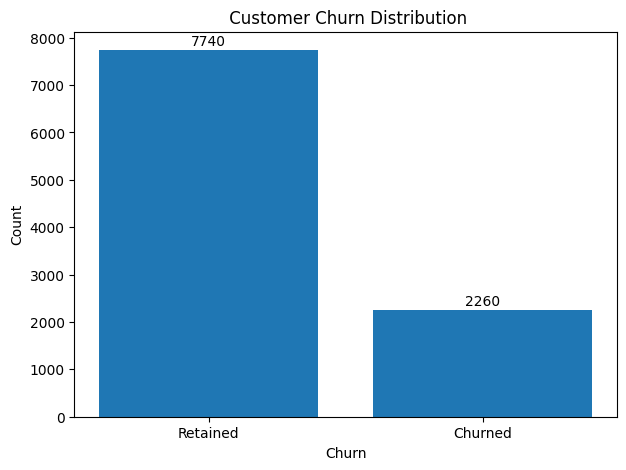

In [16]:
# Churn Distribution

import matplotlib.pyplot as plt

churn_counts=df['Churn'].value_counts().sort_index()

plt.figure(figsize=(7,5))

bars=plt.bar(['Retained','Churned'],
        churn_counts.values,

)
plt.title(" Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Count") 
plt.xticks([0,1],['Retained','Churned'],rotation=0)

for bar in bars:
    height=bar.get_height()
    plt.text(
        bar.get_x()+bar.get_width() /2,
        height + 100,
        f'{int(height)}',
        ha='center',
        fontsize=10
    )
plt.savefig(
    "Churn Distribution.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


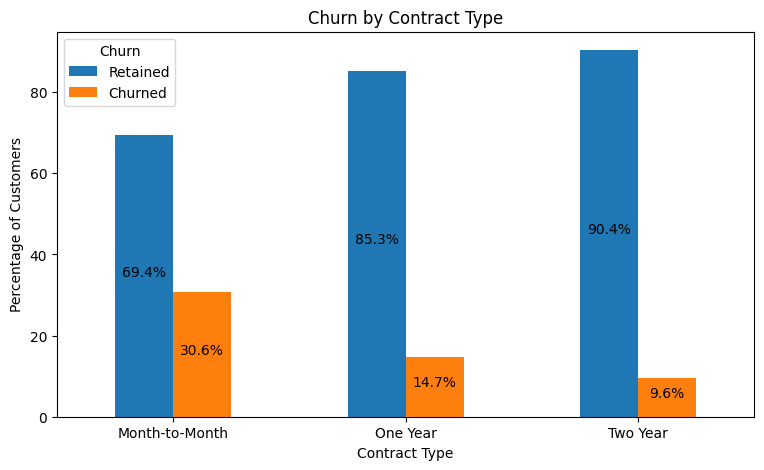

In [18]:
# Churn by contract type

contract_churn=pd.crosstab(
    df['Contract_Type'],
    df['Churn'],
    normalize='index')*100
    


contract_churn=contract_churn.rename(
    columns={0:'Retained',1:'Churned'}
)

ax=contract_churn.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title='Churn')

for container in ax.containers:
    ax.bar_label(
        container, 
        fmt='%.1f%%', 
        label_type='center', fontsize=10,
        padding=3
    )
plt.savefig(
    "Churn by Contract Type.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

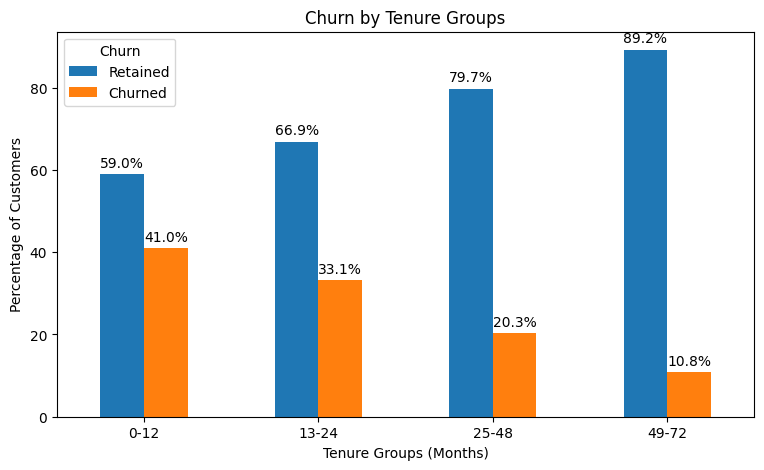

In [19]:
#Churn by tenure

df['Tenure_Groups']=pd.cut(
    df['Tenure_Months'],
    bins=[0,12,24,48,72],
    labels=['0-12','13-24','25-48','49-72']
)

tenure_churn=pd.crosstab(
    df['Tenure_Groups'],
    df['Churn'],
    normalize='index')*100

tenure_churn=tenure_churn.rename(
    columns={0:'Retained',1:'Churned'}
)

ax=tenure_churn.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title("Churn by Tenure Groups")
plt.xlabel("Tenure Groups (Months)")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title='Churn')

for container in ax.containers:
    ax.bar_label(
        container, 
        fmt='%.1f%%', 
        fontsize=10,
        padding=3
    )
plt.savefig(
    "Churn by Tenure Groups.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

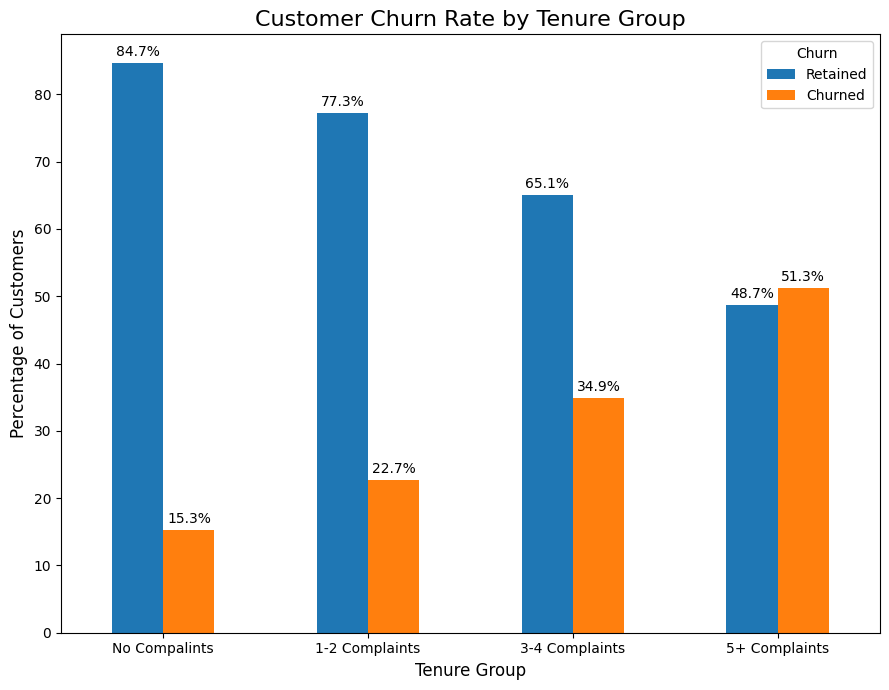

In [20]:
#Churn by Number of Complaints

df['Complaint_Group']=pd.cut(
         df['Number_of_Complaints'],
         bins=[-1,0,2,4,float('inf')],
         labels=['No Compalints','1-2 Complaints','3-4 Complaints','5+ Complaints']
)

complaint_churn= pd.crosstab(
     df['Complaint_Group'],
     df['Churn'],
     normalize='index',
)*100

complaint_churn=complaint_churn.rename(
    columns={0:'Retained',1:'Churned'}
)

ax=complaint_churn.plot(
    kind='bar',
    figsize=(9,7)
)
plt.title('Customer Churn Rate by Tenure Group',fontsize=16)
plt.xlabel('Tenure Group',fontsize=12)
plt.ylabel('Percentage of Customers',fontsize=12)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3
    )

plt.tight_layout()

plt.savefig(
    "Churn by Number of Complaints.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

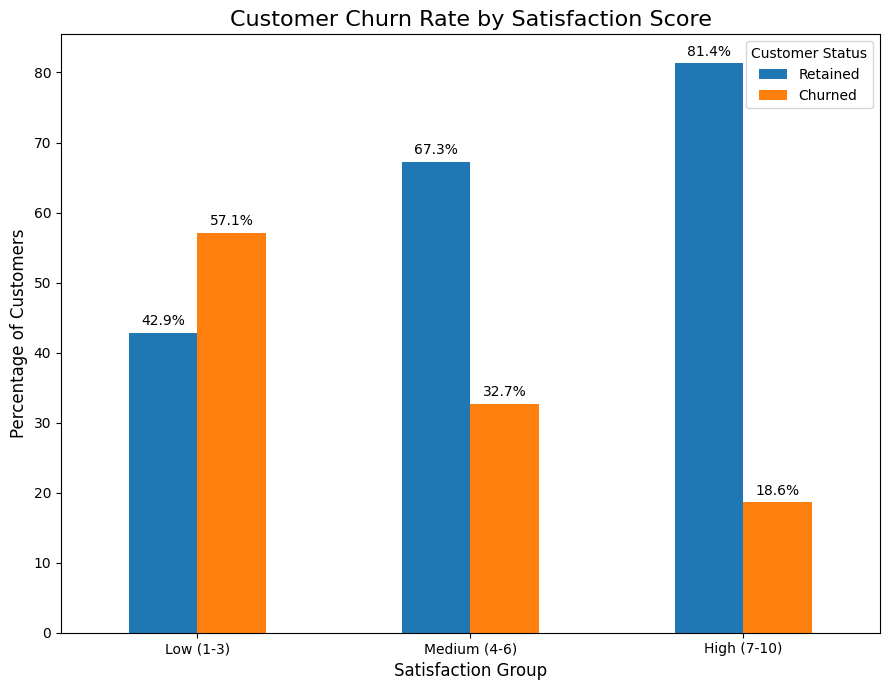

In [21]:
#Churn by Satisfaction Score

df['Satisfaction_Group'] = pd.cut(
    df['Satisfaction_Score'],
    bins=[0, 3, 6, 10],
    labels=['Low (1-3)', 'Medium (4-6)', 'High (7-10)'],
    include_lowest=True
)

satisfaction_churn = pd.crosstab(
    df['Satisfaction_Group'],
    df['Churn'],
    normalize='index'
) * 100

satisfaction_churn = satisfaction_churn.rename(
    columns={0: 'Retained', 1: 'Churned'}
)

ax=satisfaction_churn.plot(
    kind='bar',
    figsize=(9,7)
)

plt.title('Customer Churn Rate by Satisfaction Score', fontsize=16)
plt.xlabel('Satisfaction Group', fontsize=12)
plt.ylabel('Percentage of Customers', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Customer Status')

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3
    )

plt.tight_layout()
plt.savefig(
    "churn by satisfaction score.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

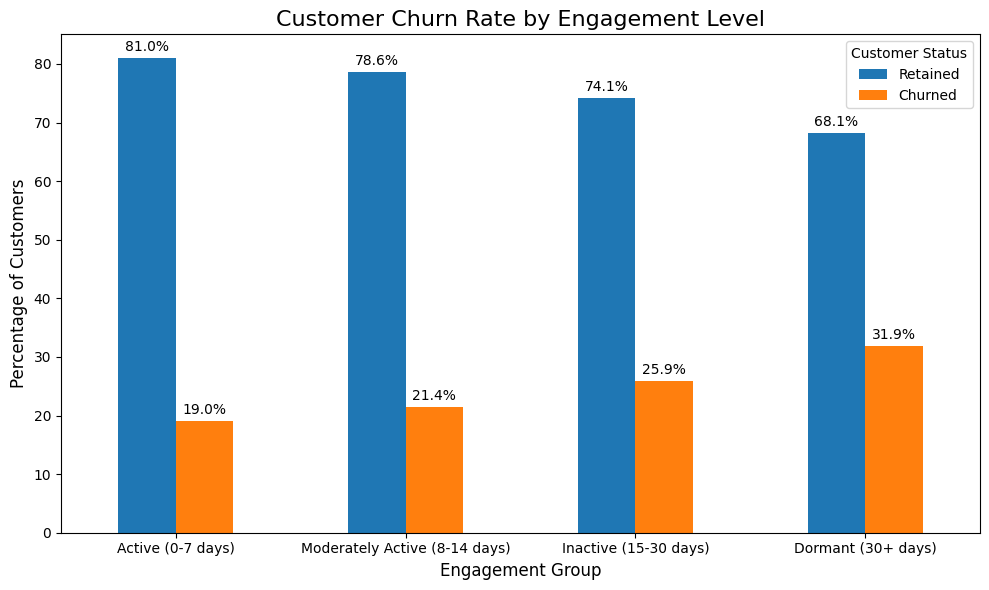

In [22]:
# Churn by Engagement Level

df['Engagement_Group'] = pd.cut(
    df['Last_Login_Days'],
    bins=[-1,7,14,30,float('inf')],
    labels=[
        'Active (0-7 days)',
        'Moderately Active (8-14 days)',
        'Inactive (15-30 days)',
        'Dormant (30+ days)'
    ]
    )
engagement_churn = pd.crosstab(
    df['Engagement_Group'],
    df['Churn'],
        normalize='index'
    ) * 100
    
churn_rate = engagement_churn.rename(
        columns={0: 'Retained', 1: 'Churned'}   
    )

ax=churn_rate.plot(
        kind='bar',
        figsize=(10, 6)
    )
    
plt.title('Customer Churn Rate by Engagement Level', fontsize=16)
plt.xlabel('Engagement Group', fontsize=12)
plt.ylabel('Percentage of Customers', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Customer Status')
    
for container in ax.containers:
    ax.bar_label(
    container,
    fmt='%.1f%%',
    padding=3
    )
plt.tight_layout()

plt.savefig(
    "churn by engagement level.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show() 
    
    

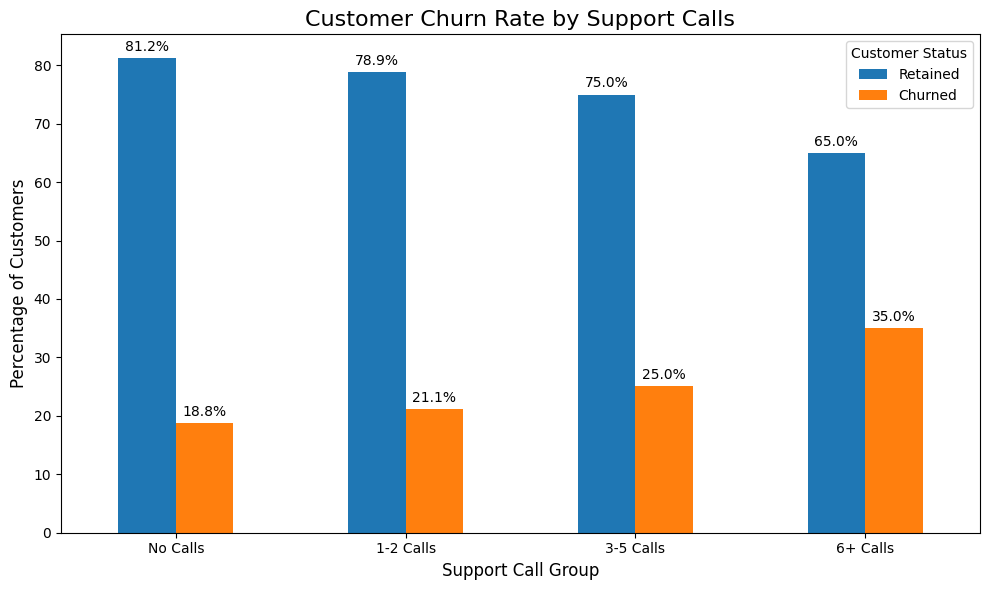

In [23]:
# Churn by Support Calls 

df['Support_Call_Group'] = pd.cut(
    df['Support_Calls'],
    bins=[-1,0,2,5,float('inf')],
    labels=['No Calls','1-2 Calls','3-5 Calls','6+ Calls']
)

support_churn = pd.crosstab(
    df['Support_Call_Group'],
    df['Churn'],
    normalize='index'
) * 100

support_churn = support_churn.rename(
    columns={0: 'Retained', 1: 'Churned'}
)

ax = support_churn.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Customer Churn Rate by Support Calls', fontsize=16)
plt.xlabel('Support Call Group', fontsize=12)
plt.ylabel('Percentage of Customers', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Customer Status')

for container in ax.containers:
    ax.bar_label(
    container,
    fmt='%.1f%%',
    padding=3
    )
plt.tight_layout()
plt.savefig(
    "churn by support calls.png",
    dpi=300,
    bbox_inches='tight'
) 
plt.show()

In [24]:
df.columns

Index(['Customer_ID', 'Gender', 'Age', 'Tenure_Months', 'Contract_Type',
       'Payment_Method', 'Monthly_Charges', 'Total_Charges',
       'Internet_Service', 'Tech_Support', 'Streaming_Service',
       'Number_of_Complaints', 'Support_Calls', 'Last_Login_Days',
       'Satisfaction_Score', 'Churn', 'Tenure_Groups', 'Complaint_Group',
       'Satisfaction_Group', 'Engagement_Group', 'Support_Call_Group'],
      dtype='object')

In [25]:
eda_columns=[
    'Tenure_Group',
    'Complaint_Group',
    'Satisfaction_Group',
    'Engagement_Group',
    'Support_Call_Group'
]

In [26]:
#Separating Features and Target

y= df['Churn']
X=df.drop(['Churn','Customer_ID'], axis=1)

In [27]:
print(X.shape)
print(y.shape)

(10000, 19)
(10000,)


In [28]:
print(X)
print(y)

      Gender  Age  Tenure_Months   Contract_Type    Payment_Method  \
0       Male   20             62        One Year     Bank Transfer   
1     Female   24              4  Month-to-Month  Electronic Check   
2     Female   43              6  Month-to-Month  Electronic Check   
3     Female   24             72  Month-to-Month     Bank Transfer   
4       Male   51             16  Month-to-Month  Electronic Check   
...      ...  ...            ...             ...               ...   
9995  Female   38             18  Month-to-Month  Electronic Check   
9996  Female   48             13        Two Year               UPI   
9997  Female   50             71  Month-to-Month               UPI   
9998    Male   30             45  Month-to-Month  Electronic Check   
9999    Male   34             62        One Year  Electronic Check   

      Monthly_Charges  Total_Charges Internet_Service Tech_Support  \
0               98.56        6066.68      No Internet          Yes   
1               60.

In [29]:
# Identifying categorical Variables

X.select_dtypes(include='object').columns

Index(['Gender', 'Contract_Type', 'Payment_Method', 'Internet_Service',
       'Tech_Support', 'Streaming_Service'],
      dtype='object')

In [30]:
# Train/Test Split and Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [31]:
# Seperating categorical and numerical features

categorical_cols=X.select_dtypes(include='object').columns.tolist()

numerical_cols=X.select_dtypes(include=['int64','float64']).columns.tolist()

print("Categorical Columns:",categorical_cols)
print("Numerical Columns:",numerical_cols)

Categorical Columns: ['Gender', 'Contract_Type', 'Payment_Method', 'Internet_Service', 'Tech_Support', 'Streaming_Service']
Numerical Columns: ['Age', 'Tenure_Months', 'Monthly_Charges', 'Total_Charges', 'Number_of_Complaints', 'Support_Calls', 'Last_Login_Days', 'Satisfaction_Score']


In [32]:
# Splitting the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [33]:
# Checking the distribution of the target variable in the training and testing sets

print('Training Data :',X_train.shape)
print('Testing Data:',X_test.shape)

print("\nTraining Set Target")
print(y_train.value_counts(normalize=True)*100)

print("\nTesting Set Target")
print(y_test.value_counts(normalize=True)*100) 

Training Data : (8000, 19)
Testing Data: (2000, 19)

Training Set Target
0    77.4
1    22.6
Name: Churn, dtype: float64

Testing Set Target
0    77.4
1    22.6
Name: Churn, dtype: float64


In [34]:
#Preprocessing Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('num',StandardScaler(), numerical_cols),
        ('cat',OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [35]:
# Building the Model Pipeline -Logistic Regression


from sklearn.linear_model import LogisticRegression

logistic_model=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ( 'model',LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [36]:
# Train the model

logistic_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [37]:
# Make prediction using the trained model

y_pred=logistic_model.predict(X_test)
print(y_pred[:20])

[0 0 1 0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0]


In [38]:
y_prob=logistic_model.predict_proba(X_test)[:,1]
print(y_prob[:20])

[0.04960361 0.25683062 0.5239907  0.03015659 0.58738892 0.11189971
 0.59079614 0.05430014 0.11641363 0.62794064 0.43031164 0.28514985
 0.09410659 0.00908466 0.34361697 0.20162653 0.30804353 0.1098729
 0.83443442 0.39913491]


In [39]:
#Evaluating the model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall   : {recall:.2f}")
print(f"F1-Score : {f1:.2f}")
print(f"ROC-AUC  : {roc_auc:.2f}")

Accuracy : 0.80
Precision: 0.63
Recall   : 0.33
F1-Score : 0.43
ROC-AUC  : 0.79


[[1460   88]
 [ 303  149]]


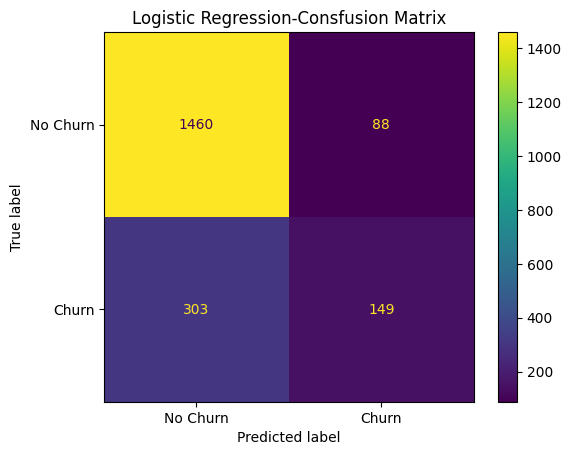

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm=confusion_matrix(y_test,y_pred)
print(cm)

disp=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn','Churn']
)
disp.plot()
plt.title("Logistic Regression-Consfusion Matrix")
plt.show()

In [41]:
# Trying a better approach by using class weighting

logistic_balanced = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

In [42]:
# Training the balanced model

logistic_balanced.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [43]:
#Prediction using balanced model

y_pred_balanced = logistic_balanced.predict(X_test)

y_prob_balanced = logistic_balanced.predict_proba(X_test)[:, 1]

In [44]:
#Evaluating the balanced model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
precision_balanced = precision_score(y_test, y_pred_balanced)
recall_balanced = recall_score(y_test, y_pred_balanced)
f1_balanced = f1_score(y_test, y_pred_balanced)
roc_auc_balanced = roc_auc_score(y_test, y_prob_balanced)

print(f"Accuracy : {accuracy_balanced:.2f}")
print(f"Precision: {precision_balanced:.2f}")
print(f"Recall   : {recall_balanced:.2f}")
print(f"F1-Score : {f1_balanced:.2f}")
print(f"ROC-AUC  : {roc_auc_balanced:.2f}") 

Accuracy : 0.71
Precision: 0.41
Recall   : 0.71
F1-Score : 0.52
ROC-AUC  : 0.79


[[1095  453]
 [ 132  320]]


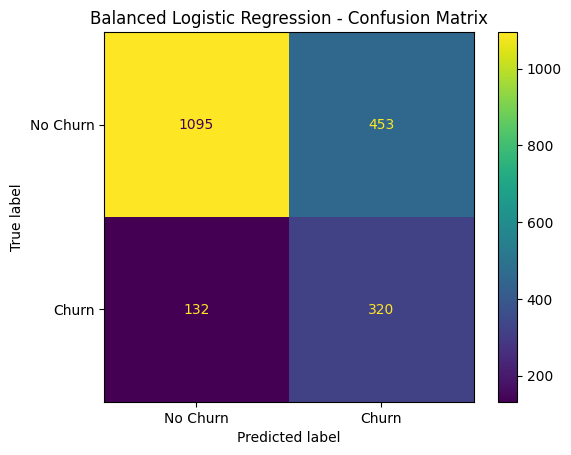

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print(cm_balanced)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=['No Churn', 'Churn']
)

disp.plot()
plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.show()

In [46]:
#Trying to test a different model-Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('model',RandomForestClassifier(
         n_estimators=200,
         random_state=42,
         class_weight='balanced',
         n_jobs=-1
))
    ]
)

In [47]:
#Training the Randomforest model

rf_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [48]:
# Creating prediction on Randomforest model

y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]


In [49]:
# Evaluating Randomforest model

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy : {accuracy_rf:.2f}")
print(f"Precision: {precision_rf:.2f}")
print(f"Recall   : {recall_rf:.2f}")
print(f"F1-Score : {f1_rf:.2f}")
print(f"ROC-AUC  : {roc_auc_rf:.2f}")

Accuracy : 0.79
Precision: 0.59
Recall   : 0.24
F1-Score : 0.34
ROC-AUC  : 0.77


In [50]:
# finding the best thresold

thresholds = np.arange(0.10, 0.71, 0.05)

for threshold in thresholds:
    y_pred_threshold = (y_prob_balanced >= threshold).astype(int)
    
    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)
    
    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.2f} | "
        f"Recall: {recall:.2f} | "
        f"F1: {f1:.2f}"
    )

Threshold: 0.10 | Precision: 0.25 | Recall: 0.99 | F1: 0.40
Threshold: 0.15 | Precision: 0.27 | Recall: 0.97 | F1: 0.42
Threshold: 0.20 | Precision: 0.29 | Recall: 0.96 | F1: 0.44
Threshold: 0.25 | Precision: 0.30 | Recall: 0.93 | F1: 0.46
Threshold: 0.30 | Precision: 0.33 | Recall: 0.90 | F1: 0.48
Threshold: 0.35 | Precision: 0.34 | Recall: 0.86 | F1: 0.49
Threshold: 0.40 | Precision: 0.37 | Recall: 0.82 | F1: 0.51
Threshold: 0.45 | Precision: 0.39 | Recall: 0.77 | F1: 0.52
Threshold: 0.50 | Precision: 0.41 | Recall: 0.71 | F1: 0.52
Threshold: 0.55 | Precision: 0.44 | Recall: 0.65 | F1: 0.53
Threshold: 0.60 | Precision: 0.48 | Recall: 0.60 | F1: 0.54
Threshold: 0.65 | Precision: 0.51 | Recall: 0.53 | F1: 0.52
Threshold: 0.70 | Precision: 0.54 | Recall: 0.44 | F1: 0.48


In [51]:
#Creating a final prediction using our thresold of 0.60

best_threshold = 0.60

y_pred_final = (y_prob_balanced >= best_threshold).astype(int)

print(y_pred_final[:20])

[0 0 1 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 1]


In [52]:
#Evaluating the model 

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_test,
    y_pred_final,
    target_names=['No Churn', 'Churn']
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

              precision    recall  f1-score   support

    No Churn       0.87      0.81      0.84      1548
       Churn       0.48      0.60      0.54       452

    accuracy                           0.76      2000
   macro avg       0.68      0.71      0.69      2000
weighted avg       0.79      0.76      0.77      2000

Confusion Matrix:
[[1256  292]
 [ 180  272]]


In [54]:
# The final balanced Logistic Regression model achieved a ROC-AUC of 0.79 and, using a 0.60 probability threshold, achieved 60% recall and 48% precision for the churn class. we are selected threshold based on the best F1-score among the tested thresholds 

#Comparing Logistic Regression and Random forest

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        0.80,
        accuracy,
        0.79
    ],
    'Precision': [
        0.63,
        precision,
        0.59
    ],
    'Recall': [
        0.33,
        recall,
        0.24
    ],
    'F1 Score': [
        0.43,
        f1,
        0.34
        ],
    'ROC-AUC': [
        0.79,
        roc_auc,
        0.77
    ]
})

print(model_comparison.round(3))

                          Model  Accuracy  Precision  Recall  F1 Score  \
0           Logistic Regression     0.800      0.630   0.330     0.430   
1  Balanced Logistic Regression     0.804      0.538   0.436     0.482   
2                 Random Forest     0.790      0.590   0.240     0.340   

   ROC-AUC  
0    0.790  
1    0.788  
2    0.770  


In [55]:
#Extracting feature importance from logistic Regression

feature_names = logistic_balanced.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = logistic_balanced.named_steps[
    'model'
].coef_[0]

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

feature_importance['Abs_Coefficient'] = (
    feature_importance['Coefficient'].abs()
)
feature_importance = feature_importance.sort_values(
    'Abs_Coefficient',
    ascending=False
)

feature_importance.head(20)


,Feature,Coefficient,Abs_Coefficient
10,cat__Contract_Type_Month-to-Month,0.858600,0.858600
12,cat__Contract_Type_Two Year,-0.804994,0.804994
1,num__Tenure_Months,-0.782171,0.782171
2,num__Monthly_Charges,0.421210,0.421210
7,num__Satisfaction_Score,-0.374869,0.374869
4,num__Number_of_Complaints,0.286460,0.286460
11,cat__Contract_Type_One Year,-0.281875,0.281875
6,num__Last_Login_Days,0.243459,0.243459
13,cat__Payment_Method_Bank Transfer,-0.186743,0.186743
17,cat__Internet_Service_DSL,-0.182887,0.182887


In [57]:
#final prediction dataset
# Using the balanced logistic model predictions generated above

df_results = X_test.copy()

df_results['Actual_Churn'] = y_test.values
df_results['Churn_Probability'] = y_prob_balanced
df_results['Predicted_Churn'] = y_pred_final

df_results['Customer_ID'] = df.loc[
    X_test.index,
    'Customer_ID'
].values

In [58]:
df_results.head()

,Gender,Age,Tenure_Months,Contract_Type,Payment_Method,Monthly_Charges,Total_Charges,Internet_Service,Tech_Support,Streaming_Service,...,Satisfaction_Score,Tenure_Groups,Complaint_Group,Satisfaction_Group,Engagement_Group,Support_Call_Group,Actual_Churn,Churn_Probability,Predicted_Churn,Customer_ID
639,Male,46,38,Two Year,Credit Card,91.62,2796.975,No Internet,Yes,Yes,...,7.6,25-48,1-2 Complaints,High (7-10),Moderately Active (8-14 days),1-2 Calls,0,0.153277,0,C100639
2386,Male,37,37,Month-to-Month,UPI,65.65,2589.210,Fiber Optic,No,No,...,7.4,25-48,1-2 Complaints,High (7-10),Inactive (15-30 days),1-2 Calls,0,0.545808,0,C102386
4621,Female,32,30,Month-to-Month,Credit Card,125.97,3984.390,Fiber Optic,Yes,Yes,...,7.3,25-48,1-2 Complaints,High (7-10),Inactive (15-30 days),3-5 Calls,0,0.790514,1,C104621
2407,Male,43,23,Two Year,Electronic Check,83.08,1895.280,DSL,No,Yes,...,9.3,13-24,No Compalints,High (7-10),Moderately Active (8-14 days),1-2 Calls,0,0.095327,0,C102407
2814,Female,35,14,Month-to-Month,Bank Transfer,81.17,2796.975,DSL,No,Yes,...,4.8,13-24,1-2 Complaints,Medium (4-6),Inactive (15-30 days),1-2 Calls,1,0.827299,1,C102814


In [59]:
#Sorting the highest risk customers

high_risk_customers = df_results.sort_values(
    'Churn_Probability',
    ascending=False
)

high_risk_customers[
    ['Churn_Probability', 'Actual_Churn', 'Predicted_Churn']
].head(10)

,Churn_Probability,Actual_Churn,Predicted_Churn
8569,0.978424,1,1
661,0.976858,0,1
2803,0.976557,1,1
7605,0.975238,1,1
5809,0.972231,1,1
389,0.957859,1,1
983,0.956913,1,1
4386,0.951345,0,1
2952,0.950527,1,1
8518,0.946007,1,1


In [60]:
df_results[
    [
        'Customer_ID',
        'Churn_Probability',
        'Actual_Churn',
        'Predicted_Churn'
    ]
].head(10)

,Customer_ID,Churn_Probability,Actual_Churn,Predicted_Churn
639,C100639,0.153277,0,0
2386,C102386,0.545808,0,0
4621,C104621,0.790514,0,1
2407,C102407,0.095327,0,0
2814,C102814,0.827299,1,1
3382,C103382,0.290988,0,0
4754,C104754,0.831642,0,1
3774,C103774,0.153261,0,0
5606,C105606,0.305935,0,0
2175,C102175,0.852626,1,1


In [61]:
#Creating risk factor

def risk_category(probability):
    if probability>=0.70:
        return 'High Risk'
    elif probability>=0.40:
        return' Medium Risk'
    else:
        return 'Low Risk'

df_results['Risk_Category'] = df_results['Churn_Probability'].apply(
    risk_category
)

In [62]:
print(df_results['Risk_Category'].value_counts())

Low Risk        993
 Medium Risk    641
High Risk       366
Name: Risk_Category, dtype: int64


In [63]:
#Overall Risk distribution

print(
    df_results.groupby('Risk_Category')['Churn_Probability']
    .mean()
    .sort_values(ascending=False)
)

Risk_Category
High Risk       0.815117
 Medium Risk    0.545637
Low Risk        0.207087
Name: Churn_Probability, dtype: float64


In [64]:
df_results[
    [
        'Customer_ID',
        'Churn_Probability',
        'Risk_Category',
        'Actual_Churn',
        'Predicted_Churn'
    ]
].sort_values(
    'Churn_Probability',
    ascending=False
).head(20)

,Customer_ID,Churn_Probability,Risk_Category,Actual_Churn,Predicted_Churn
8569,C108569,0.978424,High Risk,1,1
661,C100661,0.976858,High Risk,0,1
2803,C102803,0.976557,High Risk,1,1
7605,C107605,0.975238,High Risk,1,1
5809,C105809,0.972231,High Risk,1,1
389,C100389,0.957859,High Risk,1,1
983,C100983,0.956913,High Risk,1,1
4386,C104386,0.951345,High Risk,0,1
2952,C102952,0.950527,High Risk,1,1
8518,C108518,0.946007,High Risk,1,1


In [65]:
original_features = [
    'Gender',
    'Age',
    'Tenure_Months',
    'Contract_Type',
    'Payment_Method',
    'Monthly_Charges',
    'Total_Charges',
    'Internet_Service',
    'Tech_Support',
    'Streaming_Service',
    'Number_of_Complaints',
    'Support_Calls',
    'Last_Login_Days',
    'Satisfaction_Score'
]

df_results[original_features] = df.loc[
    df_results.index,
    original_features
]


In [66]:
df_results.head()

,Gender,Age,Tenure_Months,Contract_Type,Payment_Method,Monthly_Charges,Total_Charges,Internet_Service,Tech_Support,Streaming_Service,...,Tenure_Groups,Complaint_Group,Satisfaction_Group,Engagement_Group,Support_Call_Group,Actual_Churn,Churn_Probability,Predicted_Churn,Customer_ID,Risk_Category
639,Male,46,38,Two Year,Credit Card,91.62,2796.975,No Internet,Yes,Yes,...,25-48,1-2 Complaints,High (7-10),Moderately Active (8-14 days),1-2 Calls,0,0.153277,0,C100639,Low Risk
2386,Male,37,37,Month-to-Month,UPI,65.65,2589.210,Fiber Optic,No,No,...,25-48,1-2 Complaints,High (7-10),Inactive (15-30 days),1-2 Calls,0,0.545808,0,C102386,Medium Risk
4621,Female,32,30,Month-to-Month,Credit Card,125.97,3984.390,Fiber Optic,Yes,Yes,...,25-48,1-2 Complaints,High (7-10),Inactive (15-30 days),3-5 Calls,0,0.790514,1,C104621,High Risk
2407,Male,43,23,Two Year,Electronic Check,83.08,1895.280,DSL,No,Yes,...,13-24,No Compalints,High (7-10),Moderately Active (8-14 days),1-2 Calls,0,0.095327,0,C102407,Low Risk
2814,Female,35,14,Month-to-Month,Bank Transfer,81.17,2796.975,DSL,No,Yes,...,13-24,1-2 Complaints,Medium (4-6),Inactive (15-30 days),1-2 Calls,1,0.827299,1,C102814,High Risk


In [67]:
# create 'Risk reason'

def get_risk_reasons(row):
    reasons = []

    if row['Contract_Type'] == 'Month-to-Month':
        reasons.append('Month-to-Month Contract')

    if row['Tenure_Months'] <= 12:
        reasons.append('Low Tenure')

    if row['Number_of_Complaints'] >= 3:
        reasons.append('Multiple Complaints')

    if row['Satisfaction_Score'] <= 6:
        reasons.append('Low Satisfaction')

    if row['Last_Login_Days'] > 30:
        reasons.append('Highly Inactive')

    elif row['Last_Login_Days'] >= 15:
        reasons.append('Inactive')

    if row['Support_Calls'] >= 6:
        reasons.append('High Support Calls')

    elif row['Support_Calls'] >= 3:
        reasons.append('Moderate Support Calls')

    if row['Monthly_Charges'] >= 110:
        reasons.append('Very High Monthly Charges')

    elif row['Monthly_Charges'] >= 80:
        reasons.append('High Monthly Charges')

    return ', '.join(reasons) if reasons else 'No major risk indicators'


df_results['Risk_Reasons'] = df_results.apply(
    get_risk_reasons,
    axis=1
)

In [68]:
df_results[
    [
        'Customer_ID',
        'Churn_Probability',
        'Risk_Category',
        'Risk_Reasons',
        'Actual_Churn',
        'Predicted_Churn'
    ]
].sort_values(
    'Churn_Probability',
    ascending=False
).head(20)

,Customer_ID,Churn_Probability,Risk_Category,Risk_Reasons,Actual_Churn,Predicted_Churn
8569,C108569,0.978424,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",1,1
661,C100661,0.976858,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",0,1
2803,C102803,0.976557,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",1,1
7605,C107605,0.975238,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",1,1
5809,C105809,0.972231,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",1,1
389,C100389,0.957859,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",1,1
983,C100983,0.956913,High Risk,"Month-to-Month Contract, Low Tenure, Low Satis...",1,1
4386,C104386,0.951345,High Risk,"Month-to-Month Contract, Low Tenure, Low Satis...",0,1
2952,C102952,0.950527,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",1,1
8518,C108518,0.946007,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",1,1


In [69]:
# Adding a Recommended Retention Action

def get_recommendation(row):
    
    if row['Risk_Category'] == 'High Risk':
        
        if row['Contract_Type'] == 'Month-to-Month' and row['Tenure_Months'] <= 12:
            return 'Offer contract upgrade incentive and early-tenure retention offer'
        
        elif row['Number_of_Complaints'] >= 3:
            return 'Priority customer support and complaint resolution'
        
        elif row['Satisfaction_Score'] <= 6:
            return 'Conduct satisfaction follow-up and offer service improvement'
        
        elif row['Last_Login_Days'] > 30:
            return 'Re-engagement campaign with personalized offer'
        
        elif row['Support_Calls'] >= 6:
            return 'Assign dedicated support and resolve recurring issues'
        
        elif row['Monthly_Charges'] >= 110:
            return 'Review pricing and offer a suitable plan or discount'
        
        else:
            return 'Proactive retention call'

    elif row['Risk_Category'] == 'Medium Risk':
        return 'Monitor customer and provide targeted engagement'

    else:
        return 'Maintain engagement and loyalty benefits'


df_results['Recommended_Action'] = df_results.apply(
    get_recommendation,
    axis=1
)

In [70]:
df_results[
    [
        'Customer_ID',
        'Churn_Probability',
        'Risk_Category',
        'Risk_Reasons',
        'Recommended_Action',
        'Actual_Churn',
        'Predicted_Churn'
    ]
].sort_values(
    'Churn_Probability',
    ascending=False
).head(20)

,Customer_ID,Churn_Probability,Risk_Category,Risk_Reasons,Recommended_Action,Actual_Churn,Predicted_Churn
8569,C108569,0.978424,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...,1,1
661,C100661,0.976858,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",Conduct satisfaction follow-up and offer servi...,0,1
2803,C102803,0.976557,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",Conduct satisfaction follow-up and offer servi...,1,1
7605,C107605,0.975238,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...,1,1
5809,C105809,0.972231,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",Conduct satisfaction follow-up and offer servi...,1,1
389,C100389,0.957859,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...,1,1
983,C100983,0.956913,High Risk,"Month-to-Month Contract, Low Tenure, Low Satis...",Offer contract upgrade incentive and early-ten...,1,1
4386,C104386,0.951345,High Risk,"Month-to-Month Contract, Low Tenure, Low Satis...",Offer contract upgrade incentive and early-ten...,0,1
2952,C102952,0.950527,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...,1,1
8518,C108518,0.946007,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...,1,1


In [71]:
print(df_results['Risk_Category'].value_counts())

Low Risk        993
 Medium Risk    641
High Risk       366
Name: Risk_Category, dtype: int64


In [73]:
risk_summary = (
    df_results.groupby('Risk_Category')
    .agg(
        Customers=('Customer_ID', 'count'),
        Actual_Churned=('Actual_Churn', 'sum'),
        Average_Churn_Probability=('Churn_Probability', 'mean')
    )
)

risk_summary['Actual_Churn_Rate'] = (
    risk_summary['Actual_Churned']
    / risk_summary['Customers']
    * 100
)
risk_summary = risk_summary.sort_values(
    'Average_Churn_Probability',
    ascending=False
)

print(risk_summary)

               Customers  Actual_Churned  Average_Churn_Probability  \
Risk_Category                                                         
High Risk            366             197                   0.815117   
 Medium Risk         641             173                   0.545637   
Low Risk             993              82                   0.207087   

               Actual_Churn_Rate  
Risk_Category                     
High Risk              53.825137  
 Medium Risk           26.989080  
Low Risk                8.257805  


In [74]:
# we'll create a validation set, choose the threshold using validation data, 
# and then evaluate once on the untouched test set.

from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_new.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (6400, 19)
Validation: (1600, 19)
Test: (2000, 19)


In [75]:
logistic_final = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

logistic_final.fit(X_train_new, y_train_new)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [76]:
y_prob_val = logistic_final.predict_proba(X_val)[:, 1]

print(y_prob_val[:10])

print(y_prob[:10])

[0.0592247  0.3702189  0.63661617 0.4720622  0.15889456 0.72063426
 0.31134605 0.77222354 0.47969966 0.1313938 ]
[0.04960361 0.25683062 0.5239907  0.03015659 0.58738892 0.11189971
 0.59079614 0.05430014 0.11641363 0.62794064]


In [77]:
#finding the best probability thresold

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    
    y_val_pred = (y_prob_val >= threshold).astype(int)
    
    precision = precision_score(y_val, y_val_pred)
    recall = recall_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred)
    
    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1_Score': f1
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

   Threshold  Precision    Recall  F1_Score
0       0.30   0.330339  0.914365  0.485337
1       0.35   0.355482  0.886740  0.507510
2       0.40   0.394330  0.845304  0.537786
3       0.45   0.421512  0.801105  0.552381
4       0.50   0.445161  0.762431  0.562118
5       0.55   0.485822  0.709945  0.576880
6       0.60   0.531390  0.654696  0.586634
7       0.65   0.561644  0.566298  0.563961
8       0.70   0.607639  0.483425  0.538462


In [78]:
best_threshold = threshold_df.loc[
    threshold_df['F1_Score'].idxmax(),
    'Threshold'
]

print("Best Threshold:", best_threshold)

Best Threshold: 0.6


In [79]:
best_threshold = 0.60
print("Selected Threshold:", best_threshold)

Selected Threshold: 0.6


In [80]:
# Final evaluation on the untouched test data

best_threshold = 0.60
print("Selected Threshold:", best_threshold)
y_prob_test = logistic_final.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

Selected Threshold: 0.6


In [81]:
# Final model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred_test)
precision = precision_score(y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)
roc_auc = roc_auc_score(y_test, y_prob_test)

print("Accuracy :", round(accuracy, 2))
print("Precision:", round(precision, 2))
print("Recall   :", round(recall, 2))
print("F1 Score :", round(f1, 2))
print("ROC-AUC  :", round(roc_auc, 2))

Accuracy : 0.77
Precision: 0.49
Recall   : 0.6
F1 Score : 0.54
ROC-AUC  : 0.79


In [82]:
#Comparing Logistic Regression and Random Forest

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        0.80,
        accuracy,
        0.79
    ],
    'Precision': [
        0.63,
        precision,
        0.59
    ],
    'Recall': [
        0.33,
        recall,
        0.24
    ],
    'F1 Score': [
        0.43,
        f1,
        0.34
    ],
    'ROC-AUC': [
        0.79,
        roc_auc,
        0.77
    ]
})

print(model_comparison.round(3))

                          Model  Accuracy  Precision  Recall  F1 Score  \
0           Logistic Regression     0.800      0.630   0.330     0.430   
1  Balanced Logistic Regression     0.766      0.486   0.602     0.538   
2                 Random Forest     0.790      0.590   0.240     0.340   

   ROC-AUC  
0    0.790  
1    0.788  
2    0.770  


In [83]:
# Regenerate df_results using the new properly trained logistic_final model and the untouched test probabilities

df_results = X_test.copy()

df_results['Actual_Churn'] = y_test.values
df_results['Churn_Probability'] = y_prob_test
df_results['Predicted_Churn'] = y_pred_test

df_results['Customer_ID'] = df.loc[
    X_test.index,
    'Customer_ID'
].values

In [84]:
df_results['Risk_Category'] = df_results['Churn_Probability'].apply(
    risk_category
)

In [85]:
df_results['Risk_Reasons'] = df_results.apply(
    get_risk_reasons,
    axis=1
)

df_results['Recommended_Action'] = df_results.apply(
    get_recommendation,
    axis=1
)

In [87]:
# Creating the final report dataset

print(df_results.columns.tolist())
print(df_results.shape)

['Gender', 'Age', 'Tenure_Months', 'Contract_Type', 'Payment_Method', 'Monthly_Charges', 'Total_Charges', 'Internet_Service', 'Tech_Support', 'Streaming_Service', 'Number_of_Complaints', 'Support_Calls', 'Last_Login_Days', 'Satisfaction_Score', 'Tenure_Groups', 'Complaint_Group', 'Satisfaction_Group', 'Engagement_Group', 'Support_Call_Group', 'Actual_Churn', 'Churn_Probability', 'Predicted_Churn', 'Customer_ID', 'Risk_Category', 'Risk_Reasons', 'Recommended_Action']
(2000, 26)


In [88]:
final_columns = [
    'Customer_ID',
    'Gender',
    'Age',
    'Tenure_Months',
    'Contract_Type',
    'Payment_Method',
    'Monthly_Charges',
    'Total_Charges',
    'Internet_Service',
    'Tech_Support',
    'Streaming_Service',
    'Number_of_Complaints',
    'Support_Calls',
    'Last_Login_Days',
    'Satisfaction_Score',
    'Churn_Probability',
    'Risk_Category',
    'Risk_Reasons',
    'Recommended_Action',
    'Actual_Churn',
    'Predicted_Churn'
]

df_final = df_results[final_columns].copy()

print(df_final.shape)

(2000, 21)


In [89]:
df_final['Churn_Probability_Pct'] = (
    df_final['Churn_Probability'] * 100
).round(2)

In [90]:
df_final[
    [
        'Customer_ID',
        'Churn_Probability_Pct',
        'Risk_Category',
        'Risk_Reasons',
        'Recommended_Action'
    ]
].head(10)

,Customer_ID,Churn_Probability_Pct,Risk_Category,Risk_Reasons,Recommended_Action
639,C100639,16.29,Low Risk,High Monthly Charges,Maintain engagement and loyalty benefits
2386,C102386,53.52,Medium Risk,"Month-to-Month Contract, Inactive",Maintain engagement and loyalty benefits
4621,C104621,78.75,High Risk,"Month-to-Month Contract, Inactive, Moderate Su...",Review pricing and offer a suitable plan or di...
2407,C102407,10.67,Low Risk,High Monthly Charges,Maintain engagement and loyalty benefits
2814,C102814,81.97,High Risk,"Month-to-Month Contract, Low Satisfaction, Ina...",Conduct satisfaction follow-up and offer servi...
3382,C103382,29.63,Low Risk,Very High Monthly Charges,Maintain engagement and loyalty benefits
4754,C104754,82.00,High Risk,"Month-to-Month Contract, Low Satisfaction, Ina...",Conduct satisfaction follow-up and offer servi...
3774,C103774,15.58,Low Risk,"Inactive, Moderate Support Calls",Maintain engagement and loyalty benefits
5606,C105606,31.82,Low Risk,"Low Tenure, Inactive, Moderate Support Calls",Maintain engagement and loyalty benefits
2175,C102175,84.45,High Risk,"Month-to-Month Contract, Low Satisfaction, Mod...",Conduct satisfaction follow-up and offer servi...


In [91]:
df_results['Risk_Reasons'] = df_results.apply(
    get_risk_reasons,
    axis=1
)

df_results['Recommended_Action'] = df_results.apply(
    get_recommendation,
    axis=1
)

In [92]:
df_results[
    [
        'Customer_ID',
        'Churn_Probability',
        'Risk_Category',
        'Risk_Reasons',
        'Recommended_Action'
    ]
].sort_values(
    'Churn_Probability',
    ascending=False
).head(10)

,Customer_ID,Churn_Probability,Risk_Category,Risk_Reasons,Recommended_Action
8569,C108569,0.975554,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...
7605,C107605,0.973822,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...
661,C100661,0.972901,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",Conduct satisfaction follow-up and offer servi...
2803,C102803,0.972393,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",Conduct satisfaction follow-up and offer servi...
5809,C105809,0.968185,High Risk,"Month-to-Month Contract, Low Satisfaction, Hig...",Conduct satisfaction follow-up and offer servi...
389,C100389,0.955082,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...
983,C100983,0.952093,High Risk,"Month-to-Month Contract, Low Tenure, Low Satis...",Offer contract upgrade incentive and early-ten...
4386,C104386,0.949589,High Risk,"Month-to-Month Contract, Low Tenure, Low Satis...",Offer contract upgrade incentive and early-ten...
2952,C102952,0.946695,High Risk,"Month-to-Month Contract, Low Tenure, Multiple ...",Offer contract upgrade incentive and early-ten...
6824,C106824,0.942054,High Risk,"Month-to-Month Contract, Multiple Complaints, ...",Priority customer support and complaint resolu...


In [93]:
output_path = "customer_churn_predictions.csv"

df_final.to_csv(
    output_path,
    index=False
)

print("File saved successfully:", output_path)

File saved successfully: customer_churn_predictions.csv


In [94]:
import os

print("File exists:", os.path.exists(output_path))
print("File size:", os.path.getsize(output_path), "bytes")

File exists: True
File size: 441595 bytes


In [95]:
print(df_final.shape)

(2000, 22)


In [96]:
print(df_final.columns.tolist())

['Customer_ID', 'Gender', 'Age', 'Tenure_Months', 'Contract_Type', 'Payment_Method', 'Monthly_Charges', 'Total_Charges', 'Internet_Service', 'Tech_Support', 'Streaming_Service', 'Number_of_Complaints', 'Support_Calls', 'Last_Login_Days', 'Satisfaction_Score', 'Churn_Probability', 'Risk_Category', 'Risk_Reasons', 'Recommended_Action', 'Actual_Churn', 'Predicted_Churn', 'Churn_Probability_Pct']


In [97]:
# Generate predictions for all the customers

X_all = X.copy()

print(X_all.shape)

(10000, 19)


In [98]:
y_prob_all = logistic_final.predict_proba(X_all)[:, 1]

In [99]:
y_pred_all = (
    y_prob_all >= best_threshold
).astype(int)

In [100]:
df_all_results = X_all.copy()

df_all_results['Customer_ID'] = df.loc[
    X_all.index,
    'Customer_ID'
].values

df_all_results['Churn_Probability'] = y_prob_all

df_all_results['Churn_Probability_Pct'] = (
    y_prob_all * 100
).round(2)

df_all_results['Predicted_Churn'] = y_pred_all

In [101]:
df_all_results['Risk_Category'] = (
    df_all_results['Churn_Probability']
    .apply(risk_category)
)

In [102]:
#Add risk reasons and recommendations

df_all_results['Risk_Reasons'] = df_all_results.apply(
    get_risk_reasons,
    axis=1
)

df_all_results['Recommended_Action'] = df_all_results.apply(
    get_recommendation,
    axis=1
)

In [103]:
print(df_all_results.shape)

(10000, 26)


In [104]:
df_all_results.head()

,Gender,Age,Tenure_Months,Contract_Type,Payment_Method,Monthly_Charges,Total_Charges,Internet_Service,Tech_Support,Streaming_Service,...,Satisfaction_Group,Engagement_Group,Support_Call_Group,Customer_ID,Churn_Probability,Churn_Probability_Pct,Predicted_Churn,Risk_Category,Risk_Reasons,Recommended_Action
0,Male,20,62,One Year,Bank Transfer,98.56,6066.68,No Internet,Yes,No,...,High (7-10),Moderately Active (8-14 days),No Calls,C100000,0.153592,15.36,0,Low Risk,High Monthly Charges,Maintain engagement and loyalty benefits
1,Female,24,4,Month-to-Month,Electronic Check,60.78,232.84,DSL,Yes,No,...,High (7-10),Inactive (15-30 days),1-2 Calls,C100001,0.693152,69.32,1,Medium Risk,"Month-to-Month Contract, Low Tenure, Inactive",Maintain engagement and loyalty benefits
2,Female,43,6,Month-to-Month,Electronic Check,103.17,571.54,No Internet,No,Yes,...,High (7-10),Inactive (15-30 days),3-5 Calls,C100002,0.889328,88.93,1,High Risk,"Month-to-Month Contract, Low Tenure, Inactive,...",Offer contract upgrade incentive and early-ten...
3,Female,24,72,Month-to-Month,Bank Transfer,68.68,5278.75,DSL,No,Yes,...,High (7-10),Inactive (15-30 days),1-2 Calls,C100003,0.146939,14.69,0,Low Risk,"Month-to-Month Contract, Inactive",Maintain engagement and loyalty benefits
4,Male,51,16,Month-to-Month,Electronic Check,110.19,1637.33,DSL,No,No,...,High (7-10),Moderately Active (8-14 days),3-5 Calls,C100004,0.737875,73.79,1,High Risk,"Month-to-Month Contract, Moderate Support Call...",Review pricing and offer a suitable plan or di...


In [105]:
print(
    df_all_results['Risk_Category']
    .value_counts()
)

Low Risk        4981
 Medium Risk    3214
High Risk       1805
Name: Risk_Category, dtype: int64


In [106]:
print(df_all_results.shape)

print(df_all_results['Risk_Category'].value_counts())

(10000, 26)
Low Risk        4981
 Medium Risk    3214
High Risk       1805
Name: Risk_Category, dtype: int64


In [107]:
risk_distribution = (
    df_all_results['Risk_Category']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(risk_distribution)

Low Risk        49.81
 Medium Risk    32.14
High Risk       18.05
Name: Risk_Category, dtype: float64


In [108]:
# Creating the final prediction dataset

final_columns = [
    'Customer_ID',
    'Gender',
    'Age',
    'Tenure_Months',
    'Contract_Type',
    'Payment_Method',
    'Monthly_Charges',
    'Total_Charges',
    'Internet_Service',
    'Tech_Support',
    'Streaming_Service',
    'Number_of_Complaints',
    'Support_Calls',
    'Last_Login_Days',
    'Satisfaction_Score',
    'Churn_Probability',
    'Churn_Probability_Pct',
    'Risk_Category',
    'Risk_Reasons',
    'Recommended_Action',
    'Predicted_Churn'
]

df_final = df_all_results[final_columns].copy()

print(df_final.shape)

(10000, 21)


In [109]:
result_file = "customer_churn_powerbi.csv"

df_final.to_csv(
    result_file,
    index=False
)

print("final dataset saved successfully!")

final dataset saved successfully!


In [110]:
import os

print("File exists:", os.path.exists(result_file))
print("File size:", os.path.getsize(result_file), "bytes")

File exists: True
File size: 2185929 bytes
